In [1]:
%pip install torch torchvision pillow

Note: you may need to restart the kernel to use updated packages.


In [19]:
import torch
import os
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

In [2]:
!unzip 'C:\Users\Asus\OneDrive\Desktop\Computer_vision\PYTORCH\Image_dataset\Classification_dataset_v3.zip'

Archive:  C:\Users\Asus\OneDrive\Desktop\Computer_vision\PYTORCH\Image_dataset\Classification_dataset_v3.zip
   creating: Classification_dataset_v3/
  inflating: Classification_dataset_v3/Dataset_info.txt  
   creating: Classification_dataset_v3/images/
   creating: Classification_dataset_v3/images/test/
   creating: Classification_dataset_v3/images/test/Cat/
  inflating: Classification_dataset_v3/images/test/Cat/cat_1000.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1001.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1002.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1003.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1004.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1005.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1006.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1007.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1008.jpg  
  inflat

In [20]:
image_dir = 'C:/Users/Asus/OneDrive/Desktop/Computer_vision/PYTORCH/Image_dataset/Classification_dataset_v3/images/train'

for label, class_dir in enumerate(os.listdir(image_dir)):
    print(label,class_dir)

0 Cat
1 Dog
2 person


In [21]:
class ImageDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []
        self.class_names = {}

        for label, class_dir in enumerate(os.listdir(image_dir)):
            self.class_names[label] = class_dir
            class_path = os.path.join(image_dir, class_dir)
            for img_name in os.listdir(class_path):
                img_path = os.path.join(class_path, img_name)
                self.image_paths.append(os.path.join(class_path,img_name))
                self.labels.append(label)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label


In [22]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean =[0.5,0.5,0.5], std = [0.5,0.5,0.5])
])

In [23]:
train_image_dir = 'C:/Users/Asus/OneDrive/Desktop/Computer_vision/PYTORCH/Image_dataset/Classification_dataset_v3/images/train'
test_image_dir = 'C:/Users/Asus/OneDrive/Desktop/Computer_vision/PYTORCH/Image_dataset/Classification_dataset_v3/images/test'

train_image_dataset = ImageDataset(train_image_dir, transform=transform)
test_image_dataset = ImageDataset(test_image_dir, transform=transform)

In [24]:
train_image_loader = DataLoader(dataset = train_image_dataset, batch_size = 32, shuffle = True)
test_image_loader = DataLoader(dataset = test_image_dataset, batch_size = 32, shuffle = False)


In [25]:
for images, labels in train_image_loader:
    print(images.shape, labels.shape)

torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([3

In [26]:
import matplotlib.pyplot as plt
import numpy as np

In [27]:
print(train_image_dataset.class_names)
print(test_image_dataset.class_names)

{0: 'Cat', 1: 'Dog', 2: 'person'}
{0: 'Cat', 1: 'Dog', 2: 'person'}


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.99215686..1.0].


torch.Size([32, 3, 128, 128]) torch.Size([32])
person
(128, 128, 3)
2


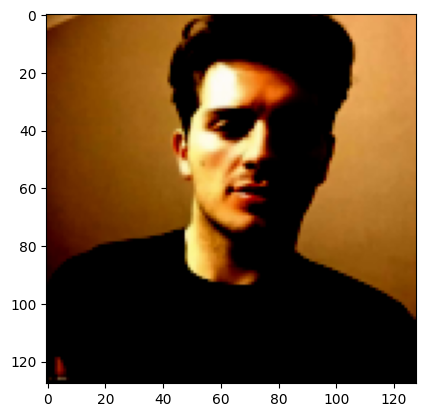

In [28]:
for images, labels in train_image_loader:
    print(images.shape, labels.shape)
    img = images[0].numpy()
    label = labels[0].item()
    print(train_image_dataset.class_names[label])
    img = np.transpose(img, (1, 2, 0))
    print(img.shape)
    print(label)
    plt.imshow(img, vmin = 0, vmax = 1)
    break


In [29]:
# Custom CNN architecture 

import torch.nn as nn
import torch.optim as optim


In [30]:
class CustomCNNModel(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(CustomCNNModel, self).__init__()
        self.input_dim = input_dim
        self.num_classes = num_classes

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self._to_linear = None
        self._get_conv_output(self.input_dim)

        self.fc_layers = nn.Sequential(
            nn.Linear(self._to_linear, 512),
            nn.ReLU(),
            nn.Linear(512,128),
            nn.ReLU(),
            nn.Linear(128, self.num_classes)
        )

    def _get_conv_output(self, input_dim = 12):
        with torch.no_grad():
            dummy_input = torch.zeros(1,3, input_dim, input_dim)
            output = self.conv_layers(dummy_input)
            self._to_linear = output.view(1,-1).size(1)


    def forward(self, x):
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1)
        x = self.fc_layers(x)
        return x

In [31]:
# Initialze the model

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

In [32]:
model = CustomCNNModel(input_dim=128, num_classes=3).to(device)


In [33]:
print(model)

CustomCNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.

In [34]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [35]:
# Training loop

epochs = 2

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_image_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_image_loader):.4f}")

Epoch [1/2], Loss: 0.8792
Epoch [2/2], Loss: 0.5484


In [36]:
torch.save(model.state_dict(), "cnn_model.pth")

In [37]:
# Evaluate the model

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_image_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Test accuracy is: {100 * correct/ total : .2f}%")



Test accuracy is:  79.00%


In [38]:
import cv2

In [44]:
class ImageClassifier:
    def __init__(self, model_path, class_names):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model = CustomCNNModel(input_dim = 128, num_classes = 3).to (self.device)
        self.model.load_state_dict(torch.load(model_path,map_location =self.device))
        self.model.eval()
        self.class_names = class_names
        self.transform = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
        ])


    def predict(self, image_path):
        image = Image.open(image_path).convert('RGB')
        input_tensor = self.transform(image).unsqueeze(0).to(self.device)
        with torch.no_grad:
            output = self.model(input_tensor)
            _, predicted = torch.max(output, 1)
        label =  self.class_names[predicted.item()]
        img = cv2.imread(image_path)
        cv2.putText(img, label, (10, 30), cv2.FONT_HERSHEY_SCRIPT_SIMPLEX, 1, (255, 0, 0), 2)
        cv2.imwrite("output_image.jpg", img)
        return label

In [46]:
classifier = ImageClassifier(
    r"C:\Users\Asus\OneDrive\Desktop\Computer_vision\PYTORCH\Image_dataset\cnn_model.pth",
    train_image_dataset.class_names
)
def predict(self, image_path):
    image = Image.open(image_path).convert('RGB')
    input_tensor = self.transform(image).unsqueeze(0).to(self.device)

    with torch.no_grad():
        output = self.model(input_tensor)
        _, predicted = torch.max(output, 1)

    label = self.class_names[predicted.item()]
    img = cv2.imread(image_path)
    cv2.putText(img, label, (10, 30), cv2.FONT_HERSHEY_SCRIPT_SIMPLEX, 1, (255, 0, 0), 2)
    cv2.imwrite("output_image.jpg", img)
    return label
print(f"Predicted class is: {label}")

Predicted class is: 2
